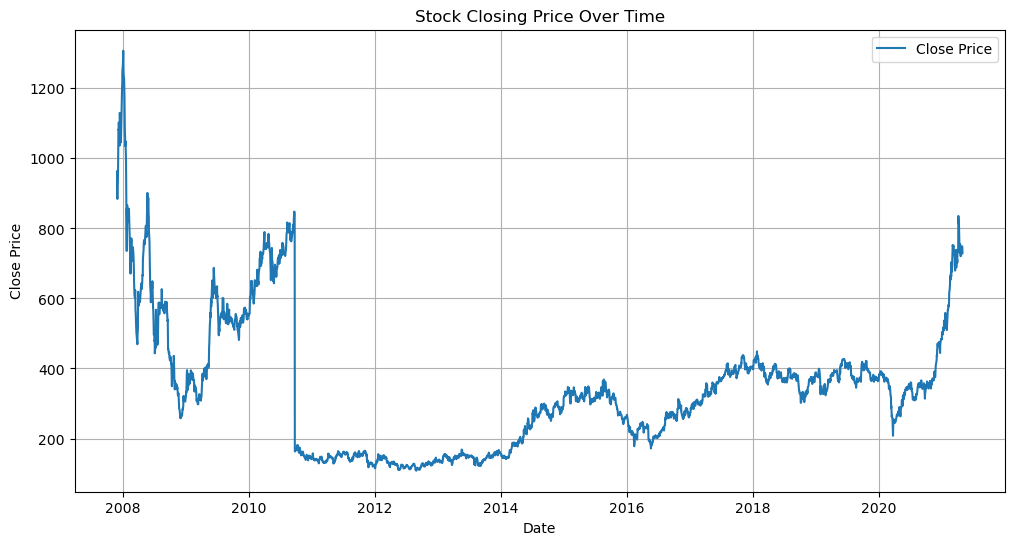

In [17]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the dataset
file_path = 'ADANIPORTS.csv'
stock_data = pd.read_csv(file_path)

# Convert 'Date' to datetime format and sort by date
stock_data['Date'] = pd.to_datetime(stock_data['Date'])
stock_data.sort_values('Date', inplace=True)

# Set the Date as the index for time series analysis
stock_data.set_index('Date', inplace=True)

# Focus on 'Close' price for forecasting
stock_data = stock_data[['Close']]

# Check for missing values
stock_data.isnull().sum()
stock_data.dropna(inplace=True)

# Plot the closing price over time
plt.figure(figsize=(12, 6))
plt.plot(stock_data['Close'], label='Close Price')
plt.title('Stock Closing Price Over Time')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()


In [18]:
# Perform the ADF Test
result = adfuller(stock_data['Close'])
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')

if result[1] > 0.05:
    print("The series is not stationary. Differencing will be applied.")
    stock_data['Close_diff'] = stock_data['Close'].diff().dropna()
else:
    print("The series is stationary.")



ADF Statistic: -3.473097683133429
p-value: 0.008705487700678824
The series is stationary.


<Figure size 1200x800 with 0 Axes>

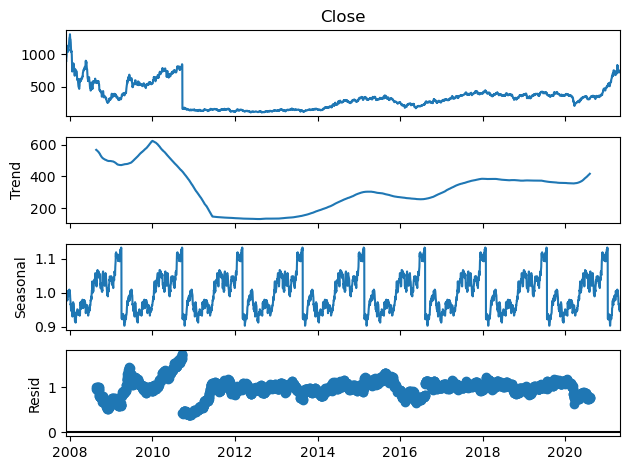

In [19]:

decomposition = seasonal_decompose(stock_data['Close'], model='multiplicative', period=365)

# Plot the decomposition components
plt.figure(figsize=(12, 8))
decomposition.plot()
plt.show()


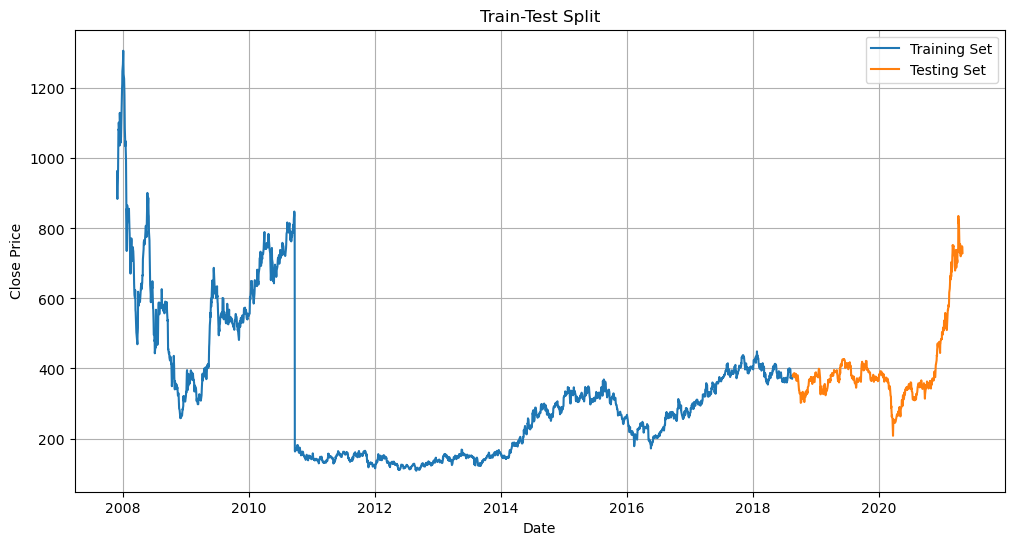

In [20]:

# Train-test split (80% training, 20% testing)
train_size = int(len(stock_data) * 0.8)
train, test = stock_data[:train_size], stock_data[train_size:]

plt.figure(figsize=(12, 6))
plt.plot(train['Close'], label='Training Set')
plt.plot(test['Close'], label='Testing Set')
plt.title('Train-Test Split')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()


C:\Users\Ruchi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Ruchi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Ruchi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\Ruchi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_predict

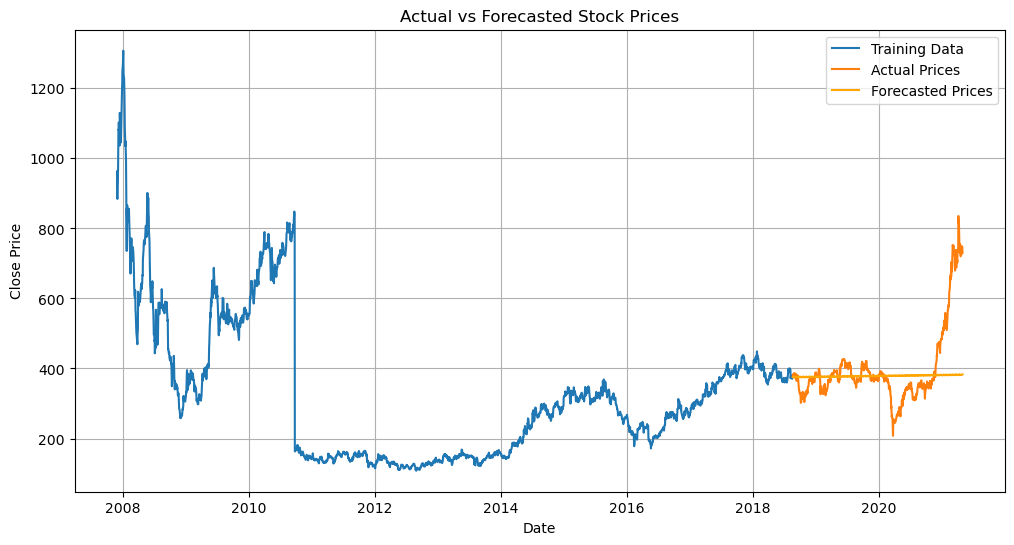

Mean Absolute Error (MAE): 61.6680334031087
Root Mean Squared Error (RMSE): 108.41598776720207


In [21]:
# Import SARIMAX from statsmodels
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit SARIMA model
model = SARIMAX(train['Close'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
model_fit = model.fit(disp=False)

# Forecast the test set
forecast = model_fit.forecast(len(test))

# Plot actual vs forecasted values
plt.figure(figsize=(12, 6))
plt.plot(train['Close'], label='Training Data')
plt.plot(test['Close'], label='Actual Prices')
plt.plot(test.index, forecast, label='Forecasted Prices', color='orange')
plt.legend()
plt.title('Actual vs Forecasted Stock Prices')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.grid(True)
plt.show()

# Evaluate model performance
mae = mean_absolute_error(test['Close'], forecast)
rmse = np.sqrt(mean_squared_error(test['Close'], forecast))
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Root Mean Squared Error (RMSE): {rmse}')


C:\Users\Ruchi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\Ruchi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


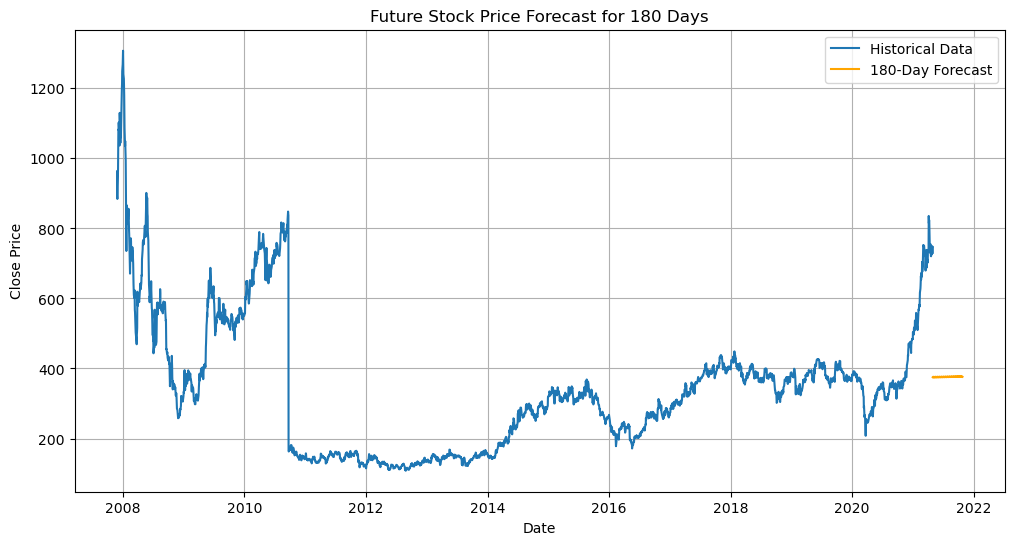

First 5 forecasted values:
2657    375.071374
2658    375.843385
2659    376.197431
2660    376.175839
2661    376.289257
Name: predicted_mean, dtype: float64
Last 5 forecasted values:
2832    377.169040
2833    376.509750
2834    376.372365
2835    376.523143
2836    376.257944
Name: predicted_mean, dtype: float64


In [23]:

# Extend the forecast to 180 days
forecast_horizon = 180
future_forecast = model_fit.forecast(forecast_horizon)

# Plot historical data with the extended forecast
plt.figure(figsize=(12, 6))
plt.plot(stock_data['Close'], label='Historical Data')
plt.plot(pd.date_range(stock_data.index[-1], periods=forecast_horizon, freq='D'), 
         future_forecast, label=f'{forecast_horizon}-Day Forecast', color='orange')
plt.legend()
plt.title(f'Future Stock Price Forecast for {forecast_horizon} Days')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.grid(True)
plt.show()

# Print summary of forecasted prices
print(f"First 5 forecasted values:\n{future_forecast[:5]}")
print(f"Last 5 forecasted values:\n{future_forecast[-5:]}")


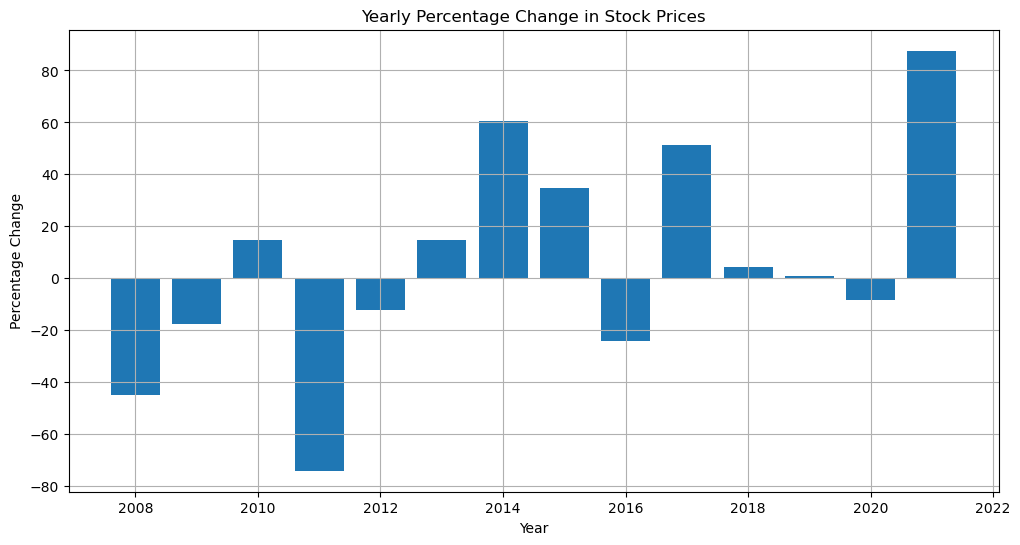

Year with highest increase: 2021
Year with lowest increase: 2011


In [24]:

# Resample data by year
stock_data_yearly = stock_data.resample('Y').mean()
stock_data_yearly['Pct_Change'] = stock_data_yearly['Close'].pct_change() * 100

# Plot yearly performance
plt.figure(figsize=(12, 6))
plt.bar(stock_data_yearly.index.year, stock_data_yearly['Pct_Change'])
plt.title('Yearly Percentage Change in Stock Prices')
plt.xlabel('Year')
plt.ylabel('Percentage Change')
plt.grid(True)
plt.show()

# Identify the year with the highest and lowest growth
max_increase_year = stock_data_yearly['Pct_Change'].idxmax().year
min_increase_year = stock_data_yearly['Pct_Change'].idxmin().year
print(f"Year with highest increase: {max_increase_year}")
print(f"Year with lowest increase: {min_increase_year}")


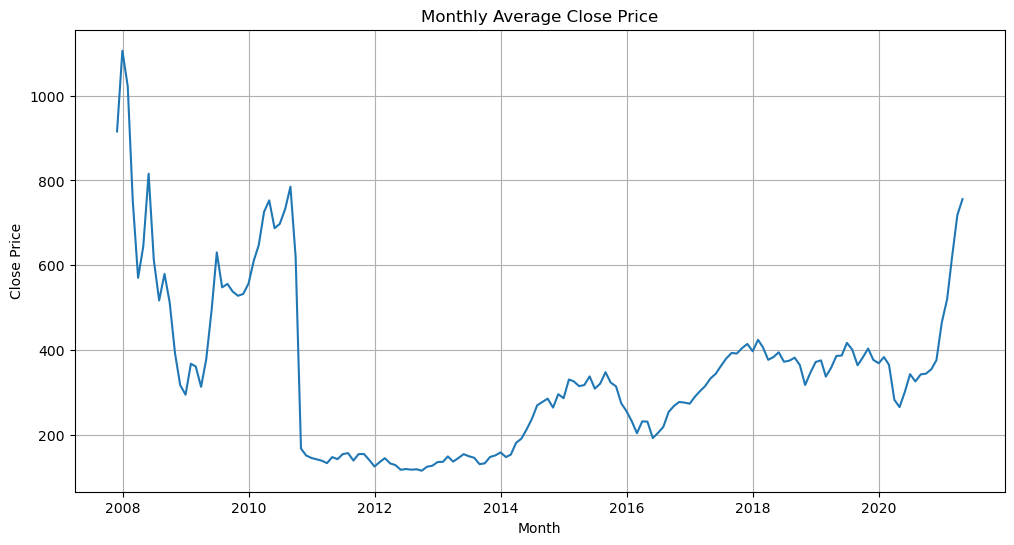

In [25]:
# Resample data by month
stock_data_monthly = stock_data.resample('M').mean()

# Plot monthly average close price
plt.figure(figsize=(12, 6))
plt.plot(stock_data_monthly['Close'], label='Monthly Average Close Price')
plt.title('Monthly Average Close Price')
plt.xlabel('Month')
plt.ylabel('Close Price')
plt.grid(True)
plt.show()
